In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
    RocCurveDisplay,
    PrecisionRecallDisplay
)


In [8]:
DATA_DIR = Path.cwd() / "dataset-csv"

EDGELIST_PATH = DATA_DIR / "txs_edgelist.csv"
CLASSES_PATH = DATA_DIR / "txs_classes.csv"
FEATURES_PATH = DATA_DIR / "txs_features.csv"

print("Dataset folder:", DATA_DIR)
print("Edge list exists:", EDGELIST_PATH.exists())
print("Classes file exists:", CLASSES_PATH.exists())
print("Features file exists:", FEATURES_PATH.exists())

Dataset folder: d:\Projects\AML_in_bitcoin\dataset-csv
Edge list exists: True
Classes file exists: True
Features file exists: True


In [9]:
edges = pd.read_csv(EDGELIST_PATH)
classes = pd.read_csv(CLASSES_PATH)
features = pd.read_csv(FEATURES_PATH)

print("Edges:", edges.shape)
print("Classes:", classes.shape)
print("Features:", features.shape)

display(edges.head())
display(classes.head())
display(features.head())

Edges: (234355, 2)
Classes: (203769, 2)
Features: (203769, 184)


,txId1,txId2
0,230425980,5530458
1,232022460,232438397
2,230460314,230459870
3,230333930,230595899
4,232013274,232029206


,txId,class
0,3321,3
1,11108,3
2,51816,3
3,68869,2
4,89273,2


,txId,Time step,Local_feature_1,Local_feature_2,Local_feature_3,Local_feature_4,Local_feature_5,Local_feature_6,Local_feature_7,Local_feature_8,...,in_BTC_min,in_BTC_max,in_BTC_mean,in_BTC_median,in_BTC_total,out_BTC_min,out_BTC_max,out_BTC_mean,out_BTC_median,out_BTC_total
0,3321,1,-0.169615,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.160199,...,0.534072,0.534072,0.534072,0.534072,0.534072,1.668990e-01,0.367074,0.266986,0.266986,0.533972
1,11108,1,-0.137586,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.127429,...,5.611878,5.611878,5.611878,5.611878,5.611878,5.861940e-01,5.025584,2.805889,2.805889,5.611778
2,51816,1,-0.170103,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.160699,...,0.456608,0.456608,0.456608,0.456608,0.456608,2.279902e-01,0.228518,0.228254,0.228254,0.456508
3,68869,1,-0.114267,-0.184668,-1.201369,0.028105,-0.043875,-0.113002,0.547008,-0.161652,...,0.308900,8.000000,3.102967,1.000000,9.308900,1.229000e+00,8.079800,4.654400,4.654400,9.308800
4,89273,1,5.202107,-0.210553,-1.756361,-0.121970,260.090707,-0.113002,-0.061584,5.335864,...,852.164680,852.164680,852.164680,852.164680,852.164680,1.300000e-07,41.264036,0.065016,0.000441,852.164680


In [10]:
print("EDGE LIST")
print(edges.columns.tolist())
display(edges.head())

print("\nCLASSES")
print(classes.columns.tolist())
display(classes.head())

print("\nFEATURES")
print("Shape:", features.shape)
print("Number of columns:", len(features.columns))
display(features.head())

EDGE LIST
['txId1', 'txId2']


,txId1,txId2
0,230425980,5530458
1,232022460,232438397
2,230460314,230459870
3,230333930,230595899
4,232013274,232029206



CLASSES
['txId', 'class']


,txId,class
0,3321,3
1,11108,3
2,51816,3
3,68869,2
4,89273,2



FEATURES
Shape: (203769, 184)
Number of columns: 184


,txId,Time step,Local_feature_1,Local_feature_2,Local_feature_3,Local_feature_4,Local_feature_5,Local_feature_6,Local_feature_7,Local_feature_8,...,in_BTC_min,in_BTC_max,in_BTC_mean,in_BTC_median,in_BTC_total,out_BTC_min,out_BTC_max,out_BTC_mean,out_BTC_median,out_BTC_total
0,3321,1,-0.169615,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.160199,...,0.534072,0.534072,0.534072,0.534072,0.534072,1.668990e-01,0.367074,0.266986,0.266986,0.533972
1,11108,1,-0.137586,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.127429,...,5.611878,5.611878,5.611878,5.611878,5.611878,5.861940e-01,5.025584,2.805889,2.805889,5.611778
2,51816,1,-0.170103,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.160699,...,0.456608,0.456608,0.456608,0.456608,0.456608,2.279902e-01,0.228518,0.228254,0.228254,0.456508
3,68869,1,-0.114267,-0.184668,-1.201369,0.028105,-0.043875,-0.113002,0.547008,-0.161652,...,0.308900,8.000000,3.102967,1.000000,9.308900,1.229000e+00,8.079800,4.654400,4.654400,9.308800
4,89273,1,5.202107,-0.210553,-1.756361,-0.121970,260.090707,-0.113002,-0.061584,5.335864,...,852.164680,852.164680,852.164680,852.164680,852.164680,1.300000e-07,41.264036,0.065016,0.000441,852.164680


In [11]:
print("Class distribution:")
print(classes["class"].value_counts(dropna=False).sort_index())

print("\nUnique class labels:")
print(sorted(classes["class"].dropna().unique()))

Class distribution:
class
1      4545
2     42019
3    157205
Name: count, dtype: int64

Unique class labels:
[np.int64(1), np.int64(2), np.int64(3)]


In [12]:
print("First feature columns:")
print(features.columns[:10].tolist())

print("\nFirst class columns:")
print(classes.columns.tolist())

print("\nDuplicate transaction IDs in features:",
      features.iloc[:, 0].duplicated().sum())

print("Duplicate transaction IDs in classes:",
      classes.iloc[:, 0].duplicated().sum())

First feature columns:
['txId', 'Time step', 'Local_feature_1', 'Local_feature_2', 'Local_feature_3', 'Local_feature_4', 'Local_feature_5', 'Local_feature_6', 'Local_feature_7', 'Local_feature_8']

First class columns:
['txId', 'class']

Duplicate transaction IDs in features: 0
Duplicate transaction IDs in classes: 0


In [13]:
FEATURE_ID_COL = features.columns[0]
CLASS_ID_COL = classes.columns[0]

data = features.merge(
    classes,
    left_on=FEATURE_ID_COL,
    right_on=CLASS_ID_COL,
    how="inner",
    suffixes=("", "_label")
)

print("Merged dataset shape:", data.shape)
display(data.head())

Merged dataset shape: (203769, 185)


,txId,Time step,Local_feature_1,Local_feature_2,Local_feature_3,Local_feature_4,Local_feature_5,Local_feature_6,Local_feature_7,Local_feature_8,...,in_BTC_max,in_BTC_mean,in_BTC_median,in_BTC_total,out_BTC_min,out_BTC_max,out_BTC_mean,out_BTC_median,out_BTC_total,class
0,3321,1,-0.169615,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.160199,...,0.534072,0.534072,0.534072,0.534072,1.668990e-01,0.367074,0.266986,0.266986,0.533972,3
1,11108,1,-0.137586,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.127429,...,5.611878,5.611878,5.611878,5.611878,5.861940e-01,5.025584,2.805889,2.805889,5.611778,3
2,51816,1,-0.170103,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.160699,...,0.456608,0.456608,0.456608,0.456608,2.279902e-01,0.228518,0.228254,0.228254,0.456508,3
3,68869,1,-0.114267,-0.184668,-1.201369,0.028105,-0.043875,-0.113002,0.547008,-0.161652,...,8.000000,3.102967,1.000000,9.308900,1.229000e+00,8.079800,4.654400,4.654400,9.308800,2
4,89273,1,5.202107,-0.210553,-1.756361,-0.121970,260.090707,-0.113002,-0.061584,5.335864,...,852.164680,852.164680,852.164680,852.164680,1.300000e-07,41.264036,0.065016,0.000441,852.164680,2


In [14]:
print("Merged columns:")
print(data.columns.tolist())

print("\nClass column exists:", "class" in data.columns)

if "class" in data.columns:
    print("\nClass distribution after merging:")
    print(data["class"].value_counts(dropna=False).sort_index())

Merged columns:
['txId', 'Time step', 'Local_feature_1', 'Local_feature_2', 'Local_feature_3', 'Local_feature_4', 'Local_feature_5', 'Local_feature_6', 'Local_feature_7', 'Local_feature_8', 'Local_feature_9', 'Local_feature_10', 'Local_feature_11', 'Local_feature_12', 'Local_feature_13', 'Local_feature_14', 'Local_feature_15', 'Local_feature_16', 'Local_feature_17', 'Local_feature_18', 'Local_feature_19', 'Local_feature_20', 'Local_feature_21', 'Local_feature_22', 'Local_feature_23', 'Local_feature_24', 'Local_feature_25', 'Local_feature_26', 'Local_feature_27', 'Local_feature_28', 'Local_feature_29', 'Local_feature_30', 'Local_feature_31', 'Local_feature_32', 'Local_feature_33', 'Local_feature_34', 'Local_feature_35', 'Local_feature_36', 'Local_feature_37', 'Local_feature_38', 'Local_feature_39', 'Local_feature_40', 'Local_feature_41', 'Local_feature_42', 'Local_feature_43', 'Local_feature_44', 'Local_feature_45', 'Local_feature_46', 'Local_feature_47', 'Local_feature_48', 'Local_feat

In [15]:
print("Observed labels:", sorted(data["class"].dropna().unique()))

# Keep only the known classes if your dataset uses 1 and 2 as known labels
known_data = data[data["class"].isin([1, 2])].copy()

print("Known-label dataset shape:", known_data.shape)
print("\nKnown class distribution:")
print(known_data["class"].value_counts().sort_index())

Observed labels: [np.int64(1), np.int64(2), np.int64(3)]
Known-label dataset shape: (46564, 185)

Known class distribution:
class
1     4545
2    42019
Name: count, dtype: int64


In [16]:
exclude_cols = {
    FEATURE_ID_COL,
    CLASS_ID_COL,
    "class"
}

X = known_data.drop(
    columns=[col for col in exclude_cols if col in known_data.columns],
    errors="ignore"
)

X = X.select_dtypes(include=[np.number])
y = known_data["class"].astype(int)

# Handle invalid and missing numerical values
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Missing values remaining:", X.isna().sum().sum())
print("\nTarget labels:", sorted(y.unique()))

X shape: (46564, 183)
y shape: (46564,)
Missing values remaining: 0

Target labels: [np.int64(1), np.int64(2)]


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 37251
Testing samples: 9313


In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [19]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train_scaled, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [20]:
y_pred = model.predict(X_test_scaled)

print("Actual labels:", y_test.iloc[:20].to_list())
print("Predicted labels:", y_pred[:20].tolist())


Actual labels: [2, 1, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2]
Predicted labels: [1, 1, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 1, 1, 2, 2, 2, 1, 2, 2]


In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("Precision (weighted):",
      round(precision_score(y_test, y_pred,
                            average="weighted", zero_division=0), 4))

print("Recall (weighted):",
      round(recall_score(y_test, y_pred,
                         average="weighted", zero_division=0), 4))

print("F1-score (weighted):",
      round(f1_score(y_test, y_pred,
                     average="weighted", zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.8803
Precision (weighted): 0.938
Recall (weighted): 0.8803
F1-score (weighted): 0.8976

Classification Report:
              precision    recall  f1-score   support

           1       0.45      0.93      0.60       909
           2       0.99      0.88      0.93      8404

    accuracy                           0.88      9313
   macro avg       0.72      0.90      0.77      9313
weighted avg       0.94      0.88      0.90      9313



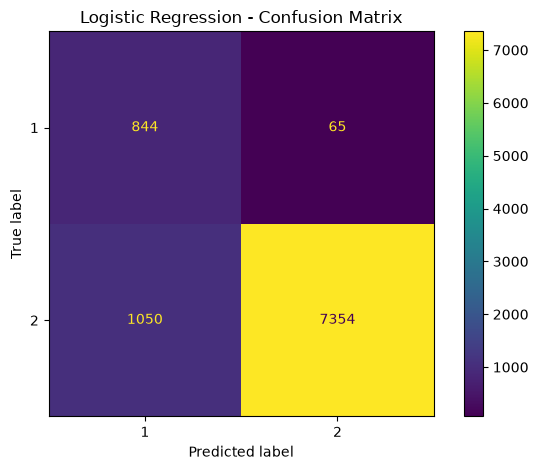

In [23]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()


In [24]:
import joblib

joblib.dump(model, DATA_DIR / "elliptic_logistic_regression.pkl")
joblib.dump(scaler, DATA_DIR / "elliptic_scaler.pkl")

print("Model saved successfully!")

Model saved successfully!
